# Outliers, Leverage, and Influence in Linear Regression

We will use a simple linear regression model

$$
Y_i=\beta_0+\beta_1X_i+\varepsilon_i
$$

and compare three different kinds of unusual observations:

$$
\boxed{
\text{Outlier}:\text{ unusual }y
}
$$

$$
\boxed{
\text{High leverage}:\text{ unusual }x
}
$$

$$
\boxed{
\text{Influential point}:\text{ substantially changes the fitted regression}
}
$$

The main goal is to see **how each type of point affects the estimated coefficients**
\[
\hat\beta_0,\hat\beta_1.
\]

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. Baseline dataset

Start with points lying close to

$
y=2x.
$

In [2]:
rng = np.random.default_rng(2)

x_base = np.array([1,2,3,4,5,6,7,8], dtype=float)
y_base = 2*x_base + rng.normal(0,0.5,len(x_base))

def fit_line(x,y):
    X = x.reshape(-1,1)
    model = LinearRegression().fit(X,y)
    yhat = model.predict(X)
    residuals = y-yhat
    return model, yhat, residuals

model_base, yhat_base, res_base = fit_line(x_base,y_base)

print(f"Baseline intercept = {model_base.intercept_:.3f}")
print(f"Baseline slope     = {model_base.coef_[0]:.3f}")

Baseline intercept = -0.362
Baseline slope     = 2.083


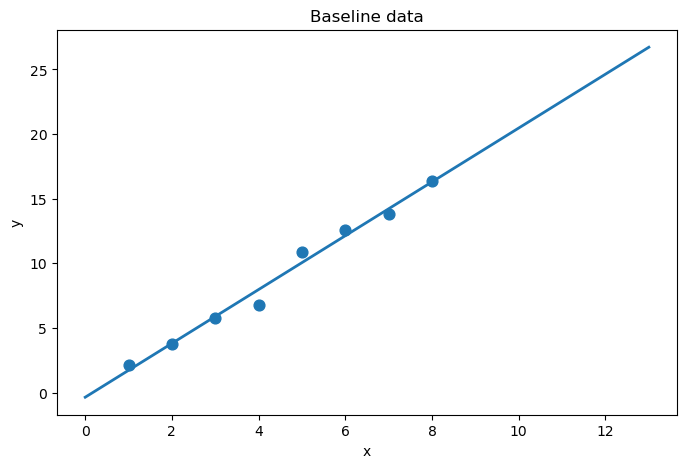

In [3]:
xx = np.linspace(0,13,200)

plt.figure(figsize=(8,5))
plt.scatter(x_base,y_base,s=60)
plt.plot(xx, model_base.intercept_ + model_base.coef_[0]*xx, linewidth=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Baseline data")
plt.show()

This fitted line will be our reference.

For simple linear regression,

$$
\hat\beta_1=
\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}
{\sum_i(x_i-\bar x)^2}.
$$

This formula already tells us why observations far from \(\bar x\) can matter so much: their contribution is multiplied by \(x_i-\bar x\).

# 2. Case A: a vertical outlier

Add a point with an ordinary predictor value but an unusual response:

$$
(x,y)=(4.5,18).
$$

Its \(x\)-value is near the center of the existing data, but its \(y\)-value is far above the trend.

In [4]:
x_out = np.append(x_base,4.5)
y_out = np.append(y_base,18)

model_out, yhat_out, res_out = fit_line(x_out,y_out)

print(f"Baseline: intercept = {model_base.intercept_:.3f}, slope = {model_base.coef_[0]:.3f}")
print(f"Outlier:  intercept = {model_out.intercept_:.3f}, slope = {model_out.coef_[0]:.3f}")

Baseline: intercept = -0.362, slope = 2.083
Outlier:  intercept = 0.637, slope = 2.083


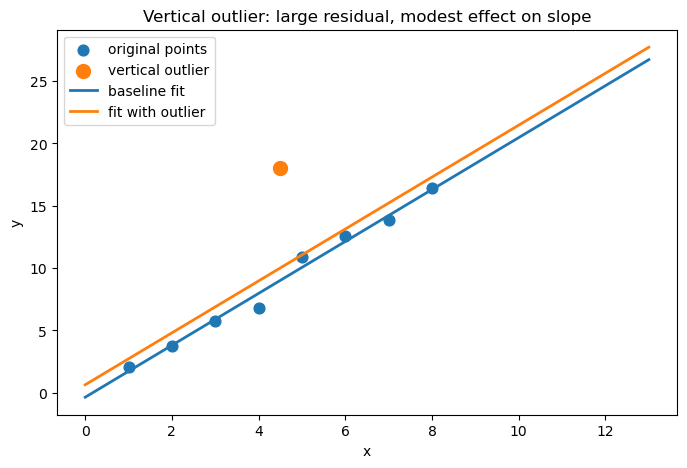

In [11]:
plt.figure(figsize=(8,5))
plt.scatter(x_base,y_base,s=60,label="original points")
plt.scatter([4.5],[18],s=100,label="vertical outlier")

plt.plot(xx, model_base.intercept_ + model_base.coef_[0]*xx,
         linewidth=2,label="baseline fit")
plt.plot(xx, model_out.intercept_ + model_out.coef_[0]*xx,
         linewidth=2,label="fit with outlier")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Vertical outlier: large residual, modest effect on slope")
plt.legend()
plt.savefig('high-res.png',dpi=500)

The point has a **large residual**, but because its \(x\)-value is near the center of the data, it has limited ability to rotate the regression line.

So:

\[
\boxed{
\text{large residual does not automatically mean large influence.}
}
\]

# 3. Case B: high leverage, but not influential

Now add a point far away in predictor space:

$$
(x,y)=(12,24).
$$

This follows the original trend \(y\approx 2x\), so its residual should be small.

In [6]:
x_lev = np.append(x_base,12)
y_lev = np.append(y_base,24)

model_lev, yhat_lev, res_lev = fit_line(x_lev,y_lev)

print(f"Baseline:      intercept = {model_base.intercept_:.3f}, slope = {model_base.coef_[0]:.3f}")
print(f"High leverage: intercept = {model_lev.intercept_:.3f}, slope = {model_lev.coef_[0]:.3f}")

Baseline:      intercept = -0.362, slope = 2.083
High leverage: intercept = -0.187, slope = 2.037


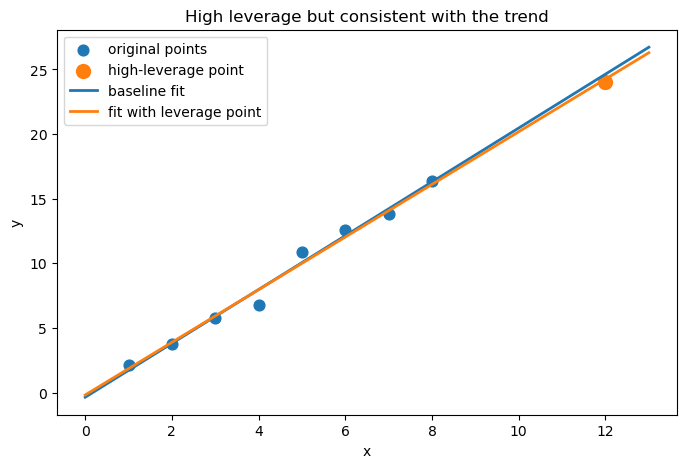

In [10]:
plt.figure(figsize=(8,5))
plt.scatter(x_base,y_base,s=60,label="original points")
plt.scatter([12],[24],s=100,label="high-leverage point")

plt.plot(xx, model_base.intercept_ + model_base.coef_[0]*xx,
         linewidth=2,label="baseline fit")
plt.plot(xx, model_lev.intercept_ + model_lev.coef_[0]*xx,
         linewidth=2,label="fit with leverage point")

plt.xlabel("x")
plt.ylabel("y")
plt.title("High leverage but consistent with the trend")
plt.legend()
plt.savefig('leverage.png',dpi=500)

This point has **high leverage** because \(x=12\) is far from the center of the observed \(x\)-values.

But it lies close to the existing trend, so it does not change the fitted coefficients much.

Thus:

\[
\boxed{
\text{high leverage means potential to affect the fit, not necessarily actual influence.}
}
\]

# 4. Case C: high leverage + off-trend = influential

Now move the same high-leverage point downward:

$$
(x,y)=(12,8).
$$

It is still far away in \(x\), but now it strongly disagrees with the existing trend.

In [8]:
x_inf = np.append(x_base,12)
y_inf = np.append(y_base,8)

model_inf, yhat_inf, res_inf = fit_line(x_inf,y_inf)

print(f"Baseline:   intercept = {model_base.intercept_:.3f}, slope = {model_base.coef_[0]:.3f}")
print(f"Influential: intercept = {model_inf.intercept_:.3f}, slope = {model_inf.coef_[0]:.3f}")

Baseline:   intercept = -0.362, slope = 2.083
Influential: intercept = 4.219, slope = 0.878


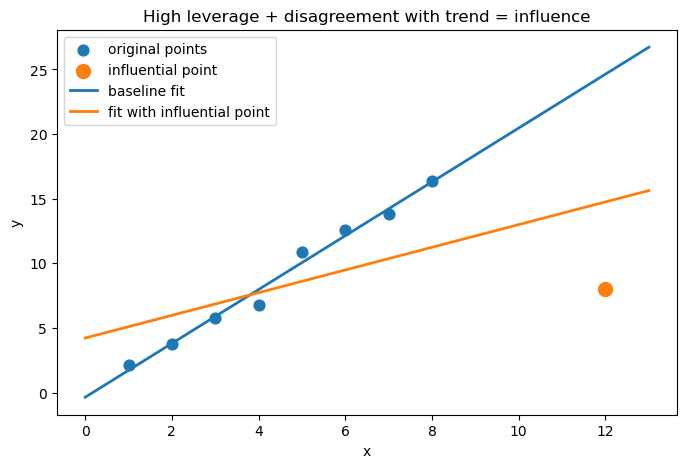

In [12]:
plt.figure(figsize=(8,5))
plt.scatter(x_base,y_base,s=60,label="original points")
plt.scatter([12],[8],s=100,label="influential point")

plt.plot(xx, model_base.intercept_ + model_base.coef_[0]*xx,
         linewidth=2,label="baseline fit")
plt.plot(xx, model_inf.intercept_ + model_inf.coef_[0]*xx,
         linewidth=2,label="fit with influential point")

plt.xlabel("x")
plt.ylabel("y")
plt.title("High leverage + disagreement with trend = influence")
plt.legend()
plt.savefig('high-influence.png',dpi=500)

Now the slope changes substantially.

Why?

Because in

$$
\hat\beta_1=
\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}
{\sum_i(x_i-\bar x)^2},
$$

the observation has a large value of

$$
|x_i-\bar x|.
$$

So its \(y_i\)-value has strong leverage over the numerator and therefore over the estimated slope.

# 5. Compare the coefficient estimates directly

In [11]:
comparison = pd.DataFrame({
    "Dataset": [
        "Baseline",
        "Vertical outlier",
        "High leverage, on trend",
        "High leverage, off trend"
    ],
    "Intercept": [
        model_base.intercept_,
        model_out.intercept_,
        model_lev.intercept_,
        model_inf.intercept_
    ],
    "Slope": [
        model_base.coef_[0],
        model_out.coef_[0],
        model_lev.coef_[0],
        model_inf.coef_[0]
    ]
})

comparison

,Dataset,Intercept,Slope
0,Baseline,-0.362054,2.083290
1,Vertical outlier,0.636529,2.083290
2,"High leverage, on trend",-0.186530,2.037100
3,"High leverage, off trend",4.219267,0.877679


The useful distinction is:

- **Vertical outlier:** large residual, but often modest effect on slope if \(x_i\) is near the center.
- **High leverage point on the trend:** unusual \(x_i\), but little coefficient change.
- **High leverage point off the trend:** unusual \(x_i\) and disagreement with the pattern; can strongly change the coefficients.

# 6. Compute leverage explicitly

For simple linear regression with an intercept,

$$
\boxed{
h_{ii}
=
\frac1n+
\frac{(x_i-\bar x)^2}
{\sum_j(x_j-\bar x)^2}
}
$$

so leverage depends entirely on the predictor values.

In [12]:
def leverage_simple(x):
    x = np.asarray(x)
    xbar = np.mean(x)
    return 1/len(x) + (x-xbar)**2 / np.sum((x-xbar)**2)

lev_out = leverage_simple(x_out)
lev_lev = leverage_simple(x_lev)
lev_inf = leverage_simple(x_inf)

print("Vertical outlier leverage:", lev_out[-1])
print("High-leverage point leverage:", lev_lev[-1])
print("Influential point leverage:", lev_inf[-1])

Vertical outlier leverage: 0.1111111111111111
High-leverage point leverage: 0.5942028985507246
Influential point leverage: 0.5942028985507246


Notice that the two points with \(x=12\) have the **same leverage**.

Leverage does not depend on \(y\).

That is why leverage measures only:

$$
\boxed{
\text{How unusual is this observation in predictor space?}
}
$$

# 7. Residual versus leverage

For each unusual point, compare:

- its residual,
- its leverage,
- and how much the slope changed.

In [13]:
rows = [
    {
        "Case":"Vertical outlier",
        "Residual of added point":res_out[-1],
        "Leverage":lev_out[-1],
        "Slope":model_out.coef_[0],
        "Change in slope":model_out.coef_[0]-model_base.coef_[0]
    },
    {
        "Case":"High leverage, on trend",
        "Residual of added point":res_lev[-1],
        "Leverage":lev_lev[-1],
        "Slope":model_lev.coef_[0],
        "Change in slope":model_lev.coef_[0]-model_base.coef_[0]
    },
    {
        "Case":"High leverage, off trend",
        "Residual of added point":res_inf[-1],
        "Leverage":lev_inf[-1],
        "Slope":model_inf.coef_[0],
        "Change in slope":model_inf.coef_[0]-model_base.coef_[0]
    }
]

pd.DataFrame(rows)

,Case,Residual of added point,Leverage,Slope,Change in slope
0,Vertical outlier,7.988665,0.111111,2.083290,0.000000
1,"High leverage, on trend",-0.258667,0.594203,2.037100,-0.046190
2,"High leverage, off trend",-6.751420,0.594203,0.877679,-1.205611


This table makes the logic explicit:

\[
\boxed{
\text{Outlier}
\Longleftrightarrow
\text{large residual}
}
\]

\[
\boxed{
\text{Leverage}
\Longleftrightarrow
\text{unusual predictor value}
}
\]

\[
\boxed{
\text{Influence}
\Longleftrightarrow
\text{large change in the fitted model}
}
\]

Influence tends to be largest when a point has both:

\[
\boxed{
\text{high leverage}
\quad+\quad
\text{substantial disagreement with the fitted trend}.
}
\]

# 8. Leave-one-out view of influence

A direct way to define influence is:

> How much would the fitted coefficients change if this observation were removed?

For observation \(i\), compare

\[
\hat\beta
\]

with

\[
\hat\beta_{(-i)},
\]

the estimate obtained after deleting observation \(i\).

In [ ]:
def leave_last_out_change(x,y):
    model_all = LinearRegression().fit(x.reshape(-1,1),y)
    model_drop = LinearRegression().fit(x[:-1].reshape(-1,1),y[:-1])
    return {
        "slope_all":model_all.coef_[0],
        "slope_without_point":model_drop.coef_[0],
        "slope_change":model_all.coef_[0]-model_drop.coef_[0],
        "intercept_all":model_all.intercept_,
        "intercept_without_point":model_drop.intercept_
    }

loo_out = leave_last_out_change(x_out,y_out)
loo_lev = leave_last_out_change(x_lev,y_lev)
loo_inf = leave_last_out_change(x_inf,y_inf)

pd.DataFrame([
    {"Case":"Vertical outlier",**loo_out},
    {"Case":"High leverage, on trend",**loo_lev},
    {"Case":"High leverage, off trend",**loo_inf}
])

# Take-home message

For a single observation \(i\), ask three different questions:

\[
\boxed{
\text{Is }y_i\text{ unusual given }x_i?
}
\]

This is about the **residual** and identifies an outlier.

\[
\boxed{
\text{Is }x_i\text{ unusual compared with the other predictors?}
}
\]

This is about **leverage**.

\[
\boxed{
\text{Would removing the point materially change }\hat\beta?
}
\]

This is about **influence**.

The three ideas are related, but they are not interchangeable.